# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import kagglehub
from google.colab import userdata
import tensorflow as tf
import os
import pprint as pp
from PIL import Image, ImageOps
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import random
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve, ConfusionMatrixDisplay)

# EDA

In [2]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia


In [3]:
!ls {path}/chest_xray/train/NORMAL | head -n 10

IM-0115-0001.jpeg
IM-0117-0001.jpeg
IM-0119-0001.jpeg
IM-0122-0001.jpeg
IM-0125-0001.jpeg
IM-0127-0001.jpeg
IM-0128-0001.jpeg
IM-0129-0001.jpeg
IM-0131-0001.jpeg
IM-0133-0001.jpeg


## Retrieval of raw images

In [4]:
# Paths of each dataset category
training_path = path + "/chest_xray/train"
testing_path = path + "/chest_xray/test"
validation_path = path + "/chest_xray/val"

In [5]:
allowed_extensions = ("png", "jpg", "jpeg")
def get_images(new_path: str):
  dataset = tf.keras.preprocessing.image_dataset_from_directory(new_path, label_mode='binary', batch_size=None, color_mode="rgb", image_size=(180,180), crop_to_aspect_ratio=False, shuffle=True)


  # pp.pprint(data_dict)

  # data_flattened = [i for i in dataset]
  # df = pd.DataFrame(data_flattened, columns=["image", "label"])
  return dataset


In [6]:
# Dataframe with two columns image & label, image: Image refrence, label: normal || pneumonia
raw_training_images = get_images(training_path)
# pp.pprint(raw_training_images)


Found 5216 files belonging to 2 classes.


In [7]:
def convert_to_panadas(dataset):
  ds_labels=[]
  for image, labels in dataset:
     ds_labels.append({"image": image.numpy(), "label": labels.numpy()[0]})
  new_df = pd.DataFrame.from_dict(ds_labels)
  return new_df


In [8]:
raw_training_images = convert_to_panadas(raw_training_images)

In [9]:
raw_testing_images = get_images(testing_path)

Found 624 files belonging to 2 classes.


In [10]:
raw_testing_images = convert_to_panadas(raw_testing_images)

In [11]:
raw_validation_images = get_images(validation_path)

Found 16 files belonging to 2 classes.


In [12]:
raw_validation_images = convert_to_panadas(raw_validation_images)

## Data analysis

<Figure size 1000x1000 with 0 Axes>

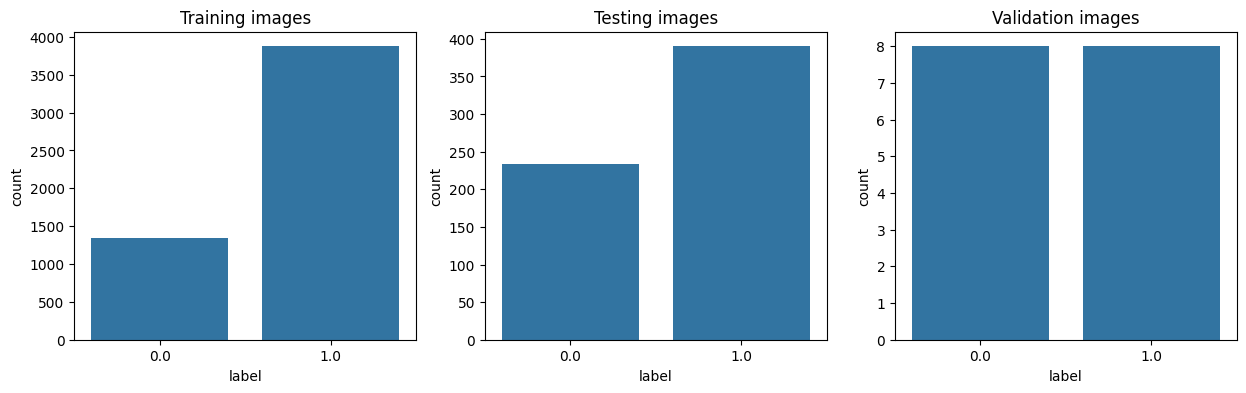

In [13]:
plt.figure(figsize=(10, 10))
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))

sns.countplot(x="label", data=raw_training_images, ax=axes[0])
axes[0].set_title("Training images")

sns.countplot(x="label", data=raw_testing_images, ax=axes[1])
axes[1].set_title("Testing images")

sns.countplot(x="label", data=raw_validation_images, ax=axes[2])
axes[2].set_title("Validation images")

plt.show()

In [14]:
training_count = raw_training_images.groupby("label").count()
testing_count = raw_testing_images.groupby("label").count()
validation_count = raw_validation_images.groupby("label").count()

stats = {
    "training": {
        "total": len(raw_training_images),
        "normal_percentage": (training_count.loc[0, "image"] * 100) / len(raw_training_images),
        "pneumonia_percentage": (training_count.loc[1, "image"] * 100) / len(raw_training_images)
    },
    "testing": {
        "total": len(raw_testing_images),
        "normal_percentage": (testing_count.loc[0, "image"] * 100) / len(raw_testing_images),
        "pneumonia_percentage": (testing_count.loc[1, "image"] * 100) / len(raw_testing_images)
    },
    "validation": {
        "total": len(raw_validation_images),
        "normal_percentage": (validation_count.loc[0, "image"] * 100) / len(raw_validation_images),
        "pneumonia_percentage": (validation_count.loc[1, "image"] * 100) / len(raw_validation_images)
    }
}

stats_df = pd.DataFrame(stats)
stats_df

,training,testing,validation
total,5216.000000,624.0,16.0
normal_percentage,25.709356,37.5,50.0
pneumonia_percentage,74.290644,62.5,50.0


### Interpretation
The class seperation in the trainnig set is very drastice compared to the other two sets, this may result on an overfitted model, which we'll need to keep a close eye on, and verify proper fitting using the validation set.

## Image resizing & sanity check

In [15]:

# def prepare_image(image: Image):
#   try:
#     # image = image.convert("RGB")
#     # image = ImageOps.fit(image, (180,180), method=Image.BILINEAR)
#     # image = image.rotate(random.randint(0, 360))
#     vectorizd = vectorizd / 255.0
#     return vectorizd
#   except Exception as e:
#     print(e)
#     return None

def scale_vector(vecotre):
  return vecotre / 255.0

### Documentation
Image data can get corrupted, so we use the image.verify sanity check.
Then we risze the image if not corrupted, to a 180x180 px, with the @cover method, while converting the color's to RGB values.

If the image failes the sanity check, the function returns None, which then will be dropped in the next step

In [16]:
scaled_training_images = raw_training_images
scaled_training_images["image"] = scaled_training_images["image"].map(scale_vector)
scaled_training_images.dropna(inplace=True)

In [17]:
scaled_testing_images = raw_testing_images.copy()
scaled_testing_images["image"] = scaled_testing_images["image"].map(scale_vector)
scaled_testing_images.dropna(inplace=True)

In [18]:
scaled_validation_images = raw_validation_images
scaled_validation_images["image"] = scaled_validation_images["image"].map(scale_vector)
scaled_validation_images.dropna(inplace=True)

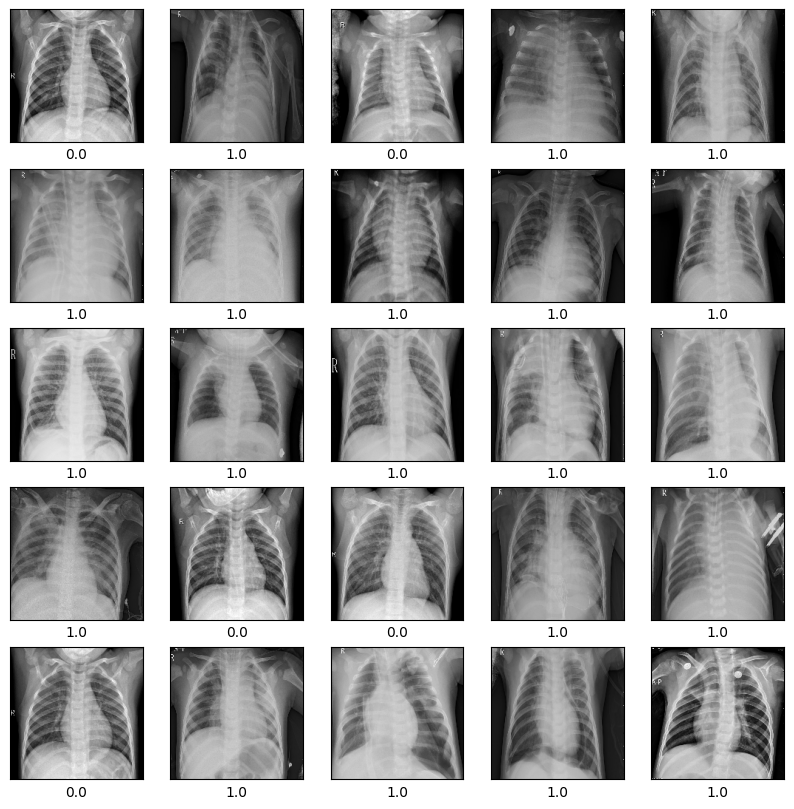

In [19]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(scaled_training_images.iloc[i]["image"])
    plt.xlabel(scaled_training_images.iloc[i]['label'])
plt.show()

In [20]:
def get_weights(df: pd.DataFrame):
  labels = df["label"].unique()
  weights = compute_class_weight(class_weight="balanced", classes=labels, y=df["label"])
  class_weights = dict(zip(labels, weights))
  return class_weights

# Modelisation

In [21]:
cnn_model = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 215168)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    13,770,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,864,129 (52.89 MB)

 Trainable params: 13,864,129 (52.89 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
cnn_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy", "precision", "recall", "auc"])

X_train = np.stack(scaled_training_images['image'].to_list()).astype("float32")
y_train = scaled_training_images['label'].to_numpy().astype("float32")

x_val = np.stack(scaled_validation_images['image'].to_list()).astype("float32")
y_val = scaled_validation_images['label'].to_numpy().astype("float32")

class_weights = {int(k): float(v) for k, v in get_weights(scaled_training_images).items()}

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_auc", mode="max", patience=5, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
)

history = cnn_model.fit(
    X_train, y_train,
    batch_size=64,
    epochs=10,
    class_weight=class_weights,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
)



Epoch 1/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 29s 186ms/step - accuracy: 0.8390 - auc: 0.9072 - loss: 0.4427 - precision: 0.9259 - recall: 0.8514 - val_accuracy: 0.8125 - val_auc: 0.9219 - val_loss: 0.3197 - val_precision: 0.8571 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 2/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.9410 - auc: 0.9816 - loss: 0.1696 - precision: 0.9775 - recall: 0.9422 - val_accuracy: 0.8125 - val_auc: 0.9688 - val_loss: 0.2214 - val_precision: 0.8571 - val_recall: 0.7500 - learning_rate: 0.0010
Epoch 3/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.9540 - auc: 0.9898 - loss: 0.1246 - precision: 0.9856 - recall: 0.9520 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2109 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 10s 75ms/step - accuracy: 0.9582 - auc: 0.9917 - loss: 0.1138 - precision: 0.9849 - recall: 0.9585 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0952 - val_

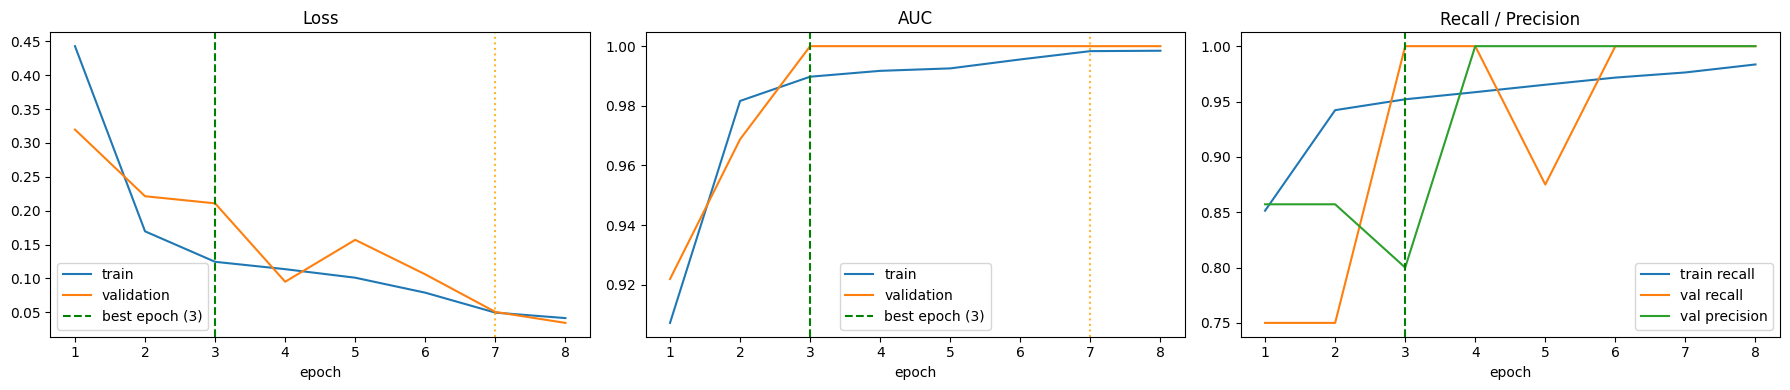

Stopped at epoch: 8 | best epoch: 3
LR reduced at epochs: [7]
Final gap  loss: -0.007 | auc: -0.002


In [23]:
h = history.history
epochs = range(1, len(h["loss"]) + 1)
best_epoch = int(np.argmax(h["val_auc"])) + 1

# epochs where the learning rate dropped
lr = h["learning_rate"]
lr_drops = [i + 1 for i in range(1, len(lr)) if lr[i] < lr[i - 1]]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, (metric, title) in zip(axes[:2], [("loss", "Loss"), ("auc", "AUC")]):
    ax.plot(epochs, h[metric], label="train")
    ax.plot(epochs, h[f"val_{metric}"], label="validation")
    ax.axvline(best_epoch, color="green", ls="--", label=f"best epoch ({best_epoch})")
    for e in lr_drops:
        ax.axvline(e, color="orange", ls=":", alpha=0.8)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()

axes[2].plot(epochs, h["recall"], label="train recall")
axes[2].plot(epochs, h["val_recall"], label="val recall")
axes[2].plot(epochs, h["val_precision"], label="val precision")
axes[2].axvline(best_epoch, color="green", ls="--")
axes[2].set_title("Recall / Precision"); axes[2].set_xlabel("epoch"); axes[2].legend()

plt.tight_layout(); plt.show()

print("Stopped at epoch:", len(epochs), "| best epoch:", best_epoch)
print("LR reduced at epochs:", lr_drops)
print(f"Final gap  loss: {h['val_loss'][-1] - h['loss'][-1]:.3f} | "
      f"auc: {h['auc'][-1] - h['val_auc'][-1]:.3f}")

In [24]:
X_test = np.stack(scaled_testing_images['image'].to_list()).astype("float32")
y_test = scaled_testing_images['label'].to_numpy().astype("int")


In [26]:
THRESHOLD = 0.5
cnn_predection = (cnn_model.predict(X_test) >= THRESHOLD).astype(int)


20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


In [63]:
joblib.dump(cnn_model, "cnn_model.joblib")

['cnn_model.joblib']

{'Accuracy': 0.7692307692307693, 'Precision': 0.7347328244274809, 'Recall': 0.9871794871794872, 'F1': 0.8424507658643327, 'ROC-AUC': np.float64(0.9235097523559063)}
              precision    recall  f1-score   support

      NORMAL       0.95      0.41      0.57       234
   PNEUMONIA       0.73      0.99      0.84       390

    accuracy                           0.77       624
   macro avg       0.84      0.70      0.71       624
weighted avg       0.82      0.77      0.74       624



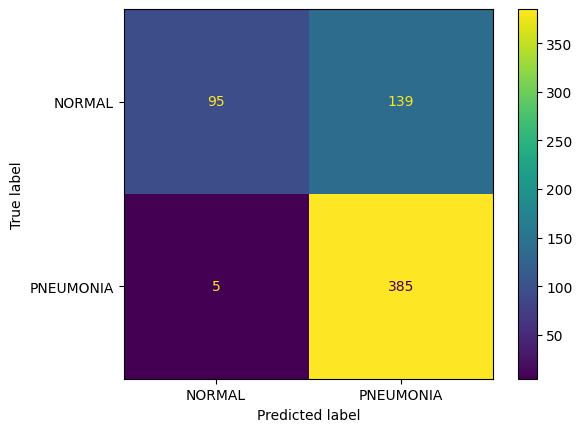

In [27]:

def evaluate(X, y, model, threshold=THRESHOLD):
    proba = model.predict(X, batch_size=64, verbose=0).ravel()
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall":    recall_score(y, pred),
        "F1":        f1_score(y, pred),
        "ROC-AUC":   roc_auc_score(y, proba),
    }, proba, pred

test_metrics, test_proba, test_pred = evaluate(X_test, y_test, cnn_model)
print(test_metrics)
print(classification_report(y_test, test_pred, target_names=["NORMAL", "PNEUMONIA"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["NORMAL", "PNEUMONIA"])
plt.show()

In [28]:
y_tr_int  = y_train.astype(int)
y_val_int = y_val.astype(int)

train_metrics, _, _ = evaluate(X_train, y_tr_int, cnn_model)
val_metrics, _, _   = evaluate(x_val, y_val_int, cnn_model)

results = pd.DataFrame({"Train": train_metrics,
                        "Validation": val_metrics,
                        "Test": test_metrics}).T.round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Train,0.979,0.992,0.979,0.986,0.998
Validation,0.875,0.800,1.000,0.889,1.000
Test,0.769,0.735,0.987,0.842,0.924


In [29]:
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, p, zero_division=0),
                 "recall": recall_score(y_test, p),
                 "specificity": tn / (tn + fp),
                 "FN (missed pneumonia)": fn,
                 "FP (false alarms)": fp})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,specificity,FN (missed pneumonia),FP (false alarms)
0,0.1,0.668,1.000,0.171,0,194
1,0.2,0.694,0.995,0.269,2,171
2,0.3,0.699,0.992,0.286,3,167
3,0.4,0.711,0.990,0.329,4,157
4,0.5,0.735,0.987,0.406,5,139
5,0.6,0.747,0.985,0.444,6,130
6,0.7,0.762,0.979,0.491,8,119
7,0.8,0.791,0.972,0.573,11,100
8,0.9,0.821,0.954,0.654,18,81


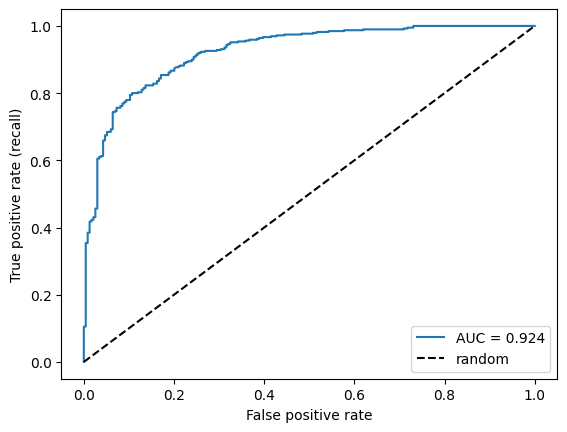

In [30]:
fpr, tpr, _ = roc_curve(y_test, test_proba)
plt.plot(fpr, tpr, label=f"AUC = {test_metrics['ROC-AUC']:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.legend(); plt.show()

In [31]:
class_names = ["NORMAL", "PNEUMONIA"]

correct = np.where(test_pred == y_test)[0]
fp_idx = np.where((test_pred == 1) & (y_test == 0))[0]
fn_idx = np.where((test_pred == 0) & (y_test == 1))[0]

print(f"Correct: {len(correct)} | FP: {len(fp_idx)} | FN: {len(fn_idx)}")

Correct: 480 | FP: 139 | FN: 5


In [32]:
def show_grid(indices, title, n=12, cols=4, seed=42):
    rng = np.random.default_rng(seed)
    if len(indices) == 0:
        print(f"No images for: {title}")
        return
    chosen = rng.choice(indices, size=min(n, len(indices)), replace=False)
    rows = int(np.ceil(len(chosen) / cols))
    plt.figure(figsize=(cols * 3.2, rows * 3.4))
    for k, i in enumerate(chosen):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(X_test[i])
        plt.axis("off")
        plt.title(f"true: {class_names[int(y_test[i])]}\n"
                  f"score: {test_proba[i]:.2f}", fontsize=9,
                  color="green" if test_pred[i] == y_test[i] else "red")
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

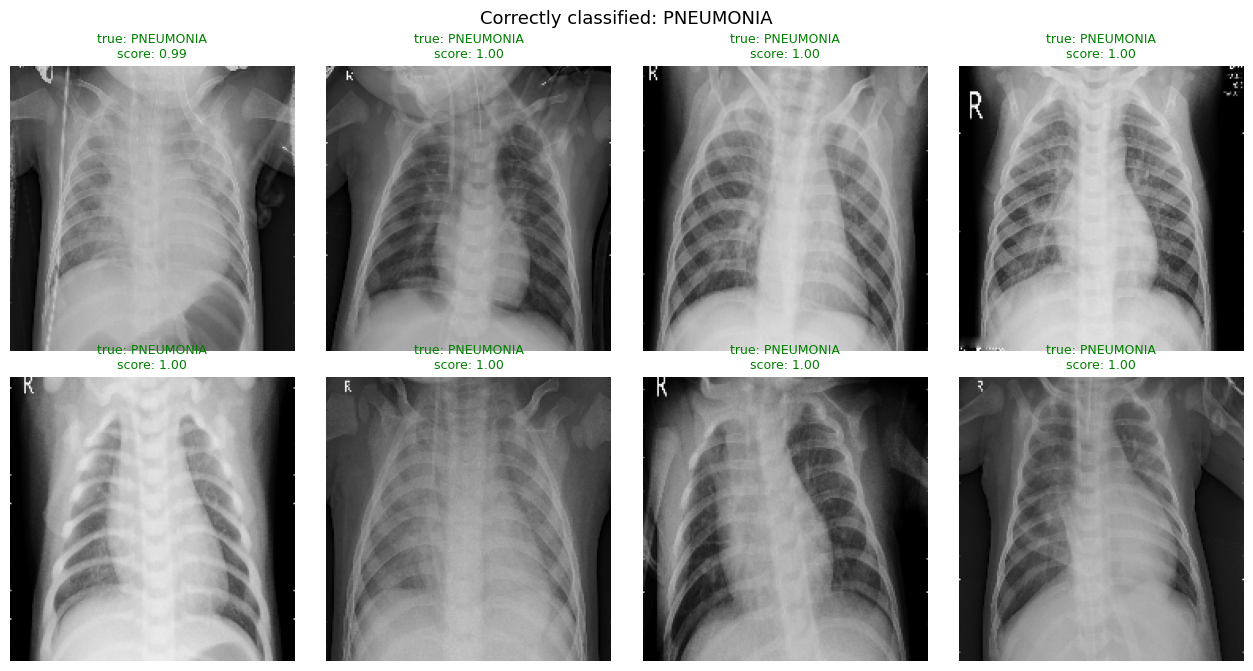

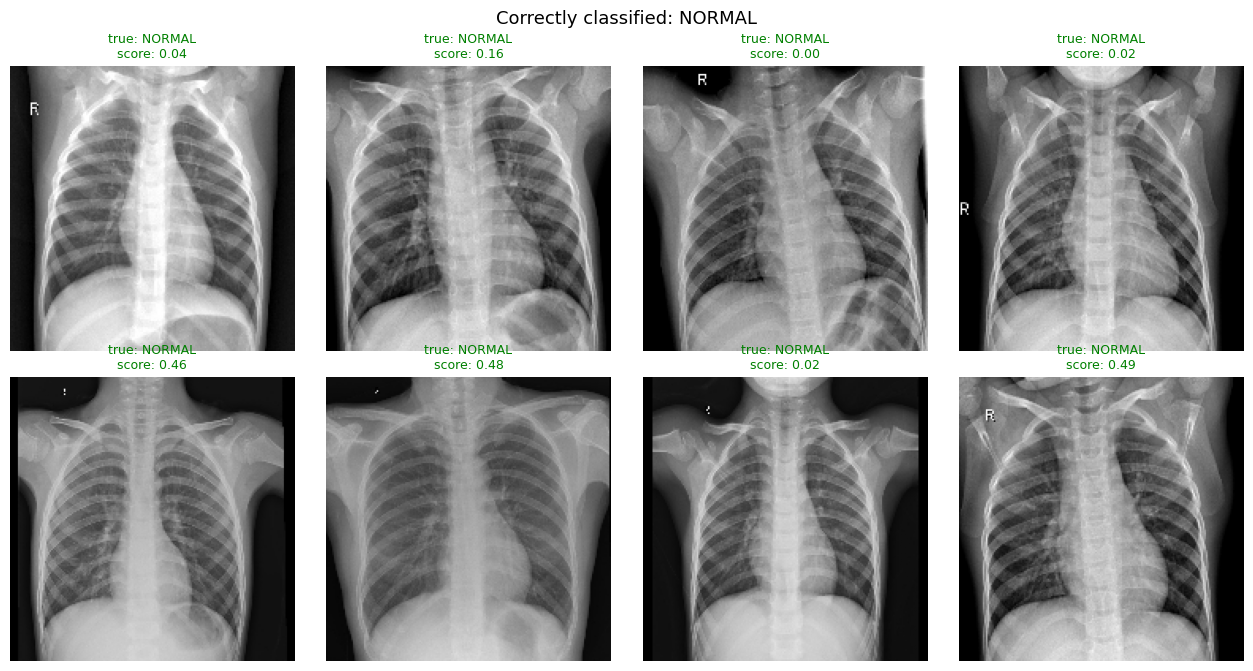

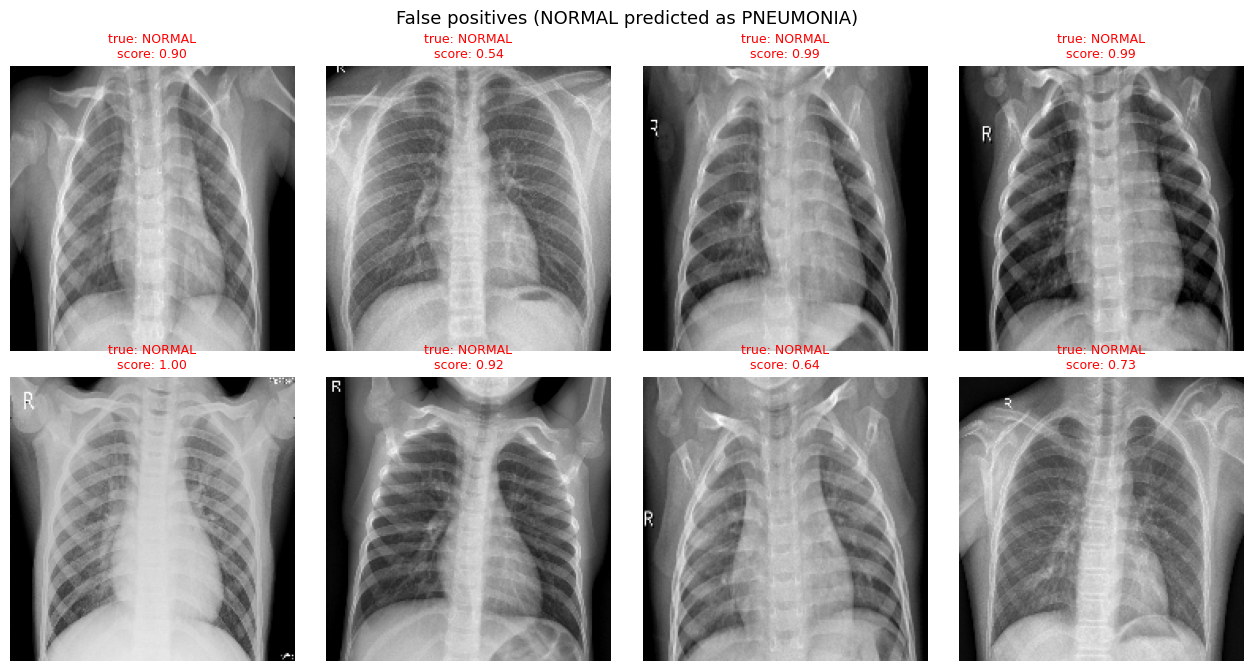

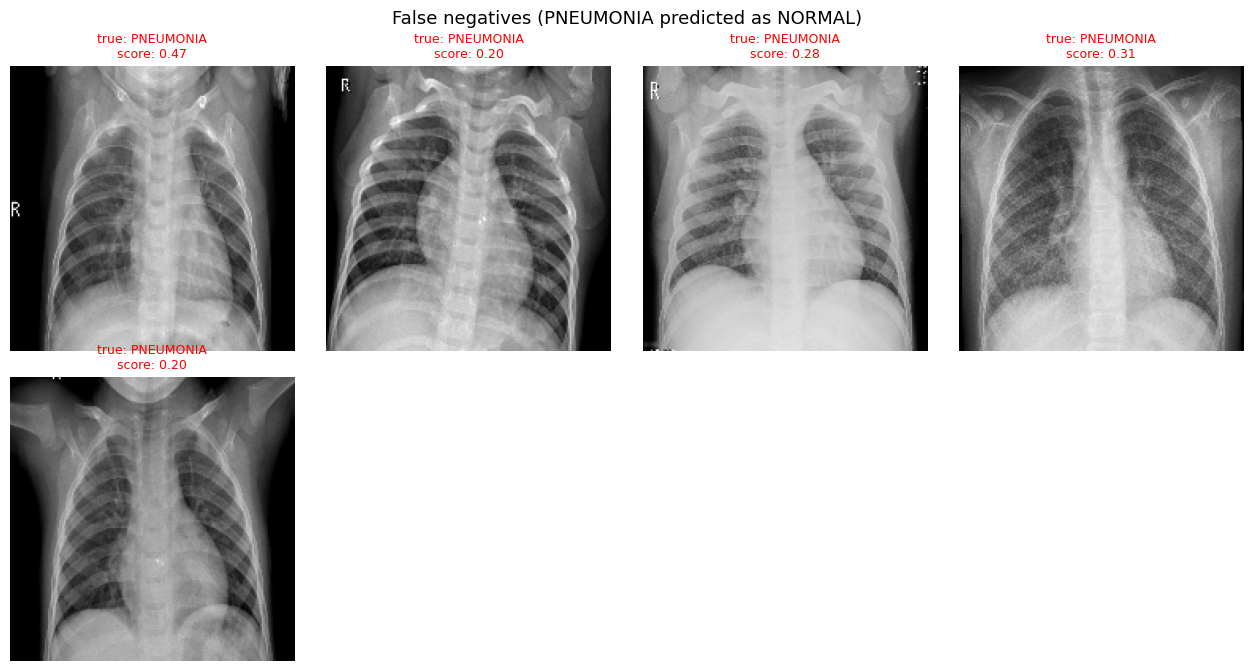

In [33]:
# Correct: show both classes
show_grid(correct[y_test[correct] == 1], "Correctly classified: PNEUMONIA", n=8)
show_grid(correct[y_test[correct] == 0], "Correctly classified: NORMAL", n=8)

# Errors
show_grid(fp_idx, "False positives (NORMAL predicted as PNEUMONIA)", n=8)
show_grid(fn_idx, "False negatives (PNEUMONIA predicted as NORMAL)", n=8)

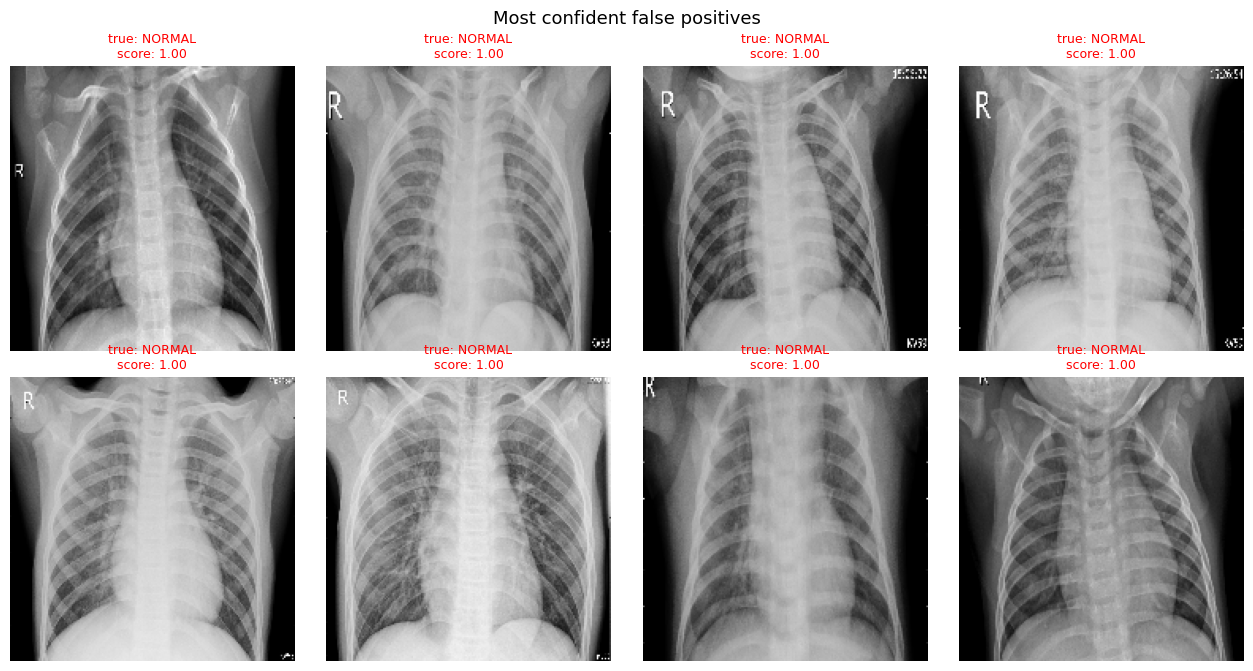

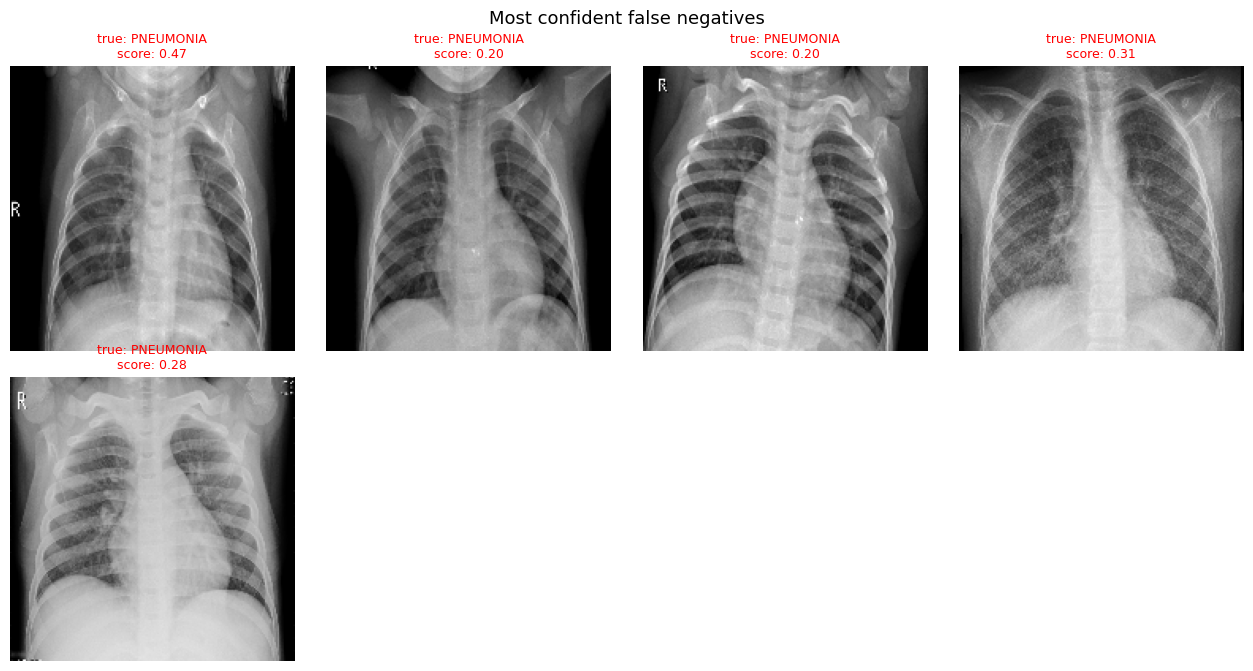

In [34]:
worst_fp = fp_idx[np.argsort(-test_proba[fp_idx])][:8]
worst_fn = fn_idx[np.argsort(test_proba[fn_idx])][:8]
show_grid(worst_fp, "Most confident false positives", n=8)
show_grid(worst_fn, "Most confident false negatives", n=8)

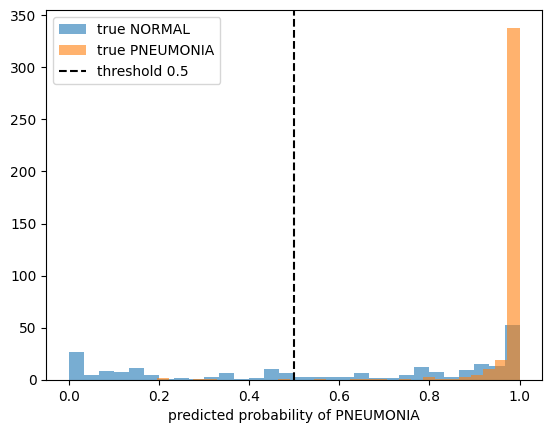

In [35]:
def stats(idx):
    imgs = X_test[idx]
    return {"n": len(idx),
            "mean brightness": imgs.mean(),
            "contrast (std)": imgs.std(axis=(1, 2, 3)).mean()}

pattern_df = pd.DataFrame({
    "Correct": stats(correct),
    "False positives": stats(fp_idx),
    "False negatives": stats(fn_idx),
}).T.round(3)
pattern_df

# Score distribution by outcome
plt.hist(test_proba[y_test == 0], bins=30, alpha=0.6, label="true NORMAL")
plt.hist(test_proba[y_test == 1], bins=30, alpha=0.6, label="true PNEUMONIA")
plt.axvline(THRESHOLD, color="k", ls="--", label=f"threshold {THRESHOLD}")
plt.xlabel("predicted probability of PNEUMONIA"); plt.legend(); plt.show()

# Transfer learninig

In [36]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow import data as tf_sdata

In [37]:
resize_fn = keras.layers.Resizing(180,180)

In [38]:
augmentation_layers = {
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)
}

def data_augmentation(x):
  for layers in augmentation_layers:
    x = layers(x)
  return x

In [39]:
base_model = MobileNetV2(
    input_shape=(180, 180, 3),
    weights="imagenet",
    include_top=False
)
base_model.trainable = False

# for layer in base_model.layers:
#   print(layer)

/tmp/ipykernel_14674/1101333421.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


In [40]:
inputs = keras.Input(shape=(180, 180, 3))
scale_layer = keras.layers.Rescaling(scale=1 / 127.5, offset=-1)
x = scale_layer(inputs)
x = base_model(inputs, training=False)

In [41]:
x = keras.layers.GlobalAveragePooling2D()(x)

In [42]:
x = layers.Dropout(0.2)(x)

In [43]:
outputs = keras.layers.Dense(1)(x)
fe_model = keras.Model(inputs, outputs)

In [44]:
fe_model.compile(
    optimizer= keras.optimizers.Adam(),
    loss= keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", "precision", "recall", "auc"]
)


In [45]:
epochs = 5
print("Fitting the top layer of the model")
ransfer_learning_history = fe_model.fit(
    X_train, y_train,
    epochs=epochs,
    class_weight=class_weights,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
    )

Fitting the top layer of the model
Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.8428 - auc: 0.9118 - loss: 0.2772 - precision: 0.9787 - recall: 0.8059 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2382 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/5
162/163 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9117 - auc: 0.9481 - loss: 0.1693 - precision: 0.9894 - recall: 0.8890
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.9174 - auc: 0.9517 - loss: 0.1604 - precision: 0.9903 - recall: 0.8975 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.2060 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9281 - auc: 0.9593 - loss: 0.1397 - precision: 0.9899 - recall: 0.9125 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.1787 - val_precision: 1.0000 - val_re

In [46]:
tf_predections = (fe_model.predict(X_test) >= THRESHOLD).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 217ms/step


In [47]:
joblib.dump(fe_model, "fe_model.joblib")

['fe_model.joblib']

# Fine tunning

In [48]:
base_model.trainable = True
for layer in base_model.layers[:101]:
  layer.trainable = False
fe_model.compile(
    optimizer= keras.optimizers.Adam(1e-5),
    loss= keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=["accuracy", "precision", "recall", "auc"]
)


In [49]:
ft_model = fe_model

In [50]:
fine_tuned_history = ft_model.fit(
    X_train, y_train,
    epochs=epochs,
    class_weight=class_weights,
    validation_data=(x_val, y_val),
    callbacks=[early_stop, reduce_lr]
    )

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 36s 67ms/step - accuracy: 0.9028 - auc: 0.9113 - loss: 0.3091 - precision: 0.9425 - recall: 0.9257 - val_accuracy: 0.8750 - val_auc: 0.8750 - val_loss: 0.4763 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9325 - auc: 0.9571 - loss: 0.1532 - precision: 0.9872 - recall: 0.9213
Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.9340 - auc: 0.9605 - loss: 0.1413 - precision: 0.9884 - recall: 0.9221 - val_accuracy: 0.7500 - val_auc: 0.8750 - val_loss: 0.5145 - val_precision: 0.6667 - val_recall: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.9488 - auc: 0.9701 - loss: 0.1055 - precision: 0.9932 - recall: 0.9375 - val_accuracy: 0.8125 - val_auc: 0.8750 - val_loss: 0.4813 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rat

In [64]:
joblib.dump(ft_model, "ft_model.joblib")

['ft_model.joblib']

# Histories

In [51]:
transfer_learning_history = ransfer_learning_history.history
fine_tuned_history = fine_tuned_history.history
cnn_history = history.history



In [52]:
histories = {"CNN": cnn_history, "FE": transfer_learning_history, "FT": fine_tuned_history}


# Comparisons

In [53]:
comparison_df = pd.DataFrame(histories).T
comparison_df = comparison_df[["val_accuracy", "val_precision", "val_recall", "val_auc"]]
comparison_df

,val_accuracy,val_precision,val_recall,val_auc
CNN,"[0.8125, 0.8125, 0.875, 1.0, 0.9375, 1.0, 1.0,...","[0.8571428656578064, 0.8571428656578064, 0.800...","[0.75, 0.75, 1.0, 1.0, 0.875, 1.0, 1.0, 1.0]","[0.921875, 0.96875, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]"
FE,"[0.9375, 1.0, 1.0, 0.9375, 1.0]","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.875, 1.0, 1.0, 0.875, 1.0]","[1.0, 1.0, 1.0, 1.0, 1.0]"
FT,"[0.875, 0.75, 0.8125, 0.8125, 0.8125]","[0.800000011920929, 0.6666666865348816, 0.7272...","[1.0, 1.0, 1.0, 1.0, 1.0]","[0.875, 0.875, 0.875, 0.8125, 0.8125]"


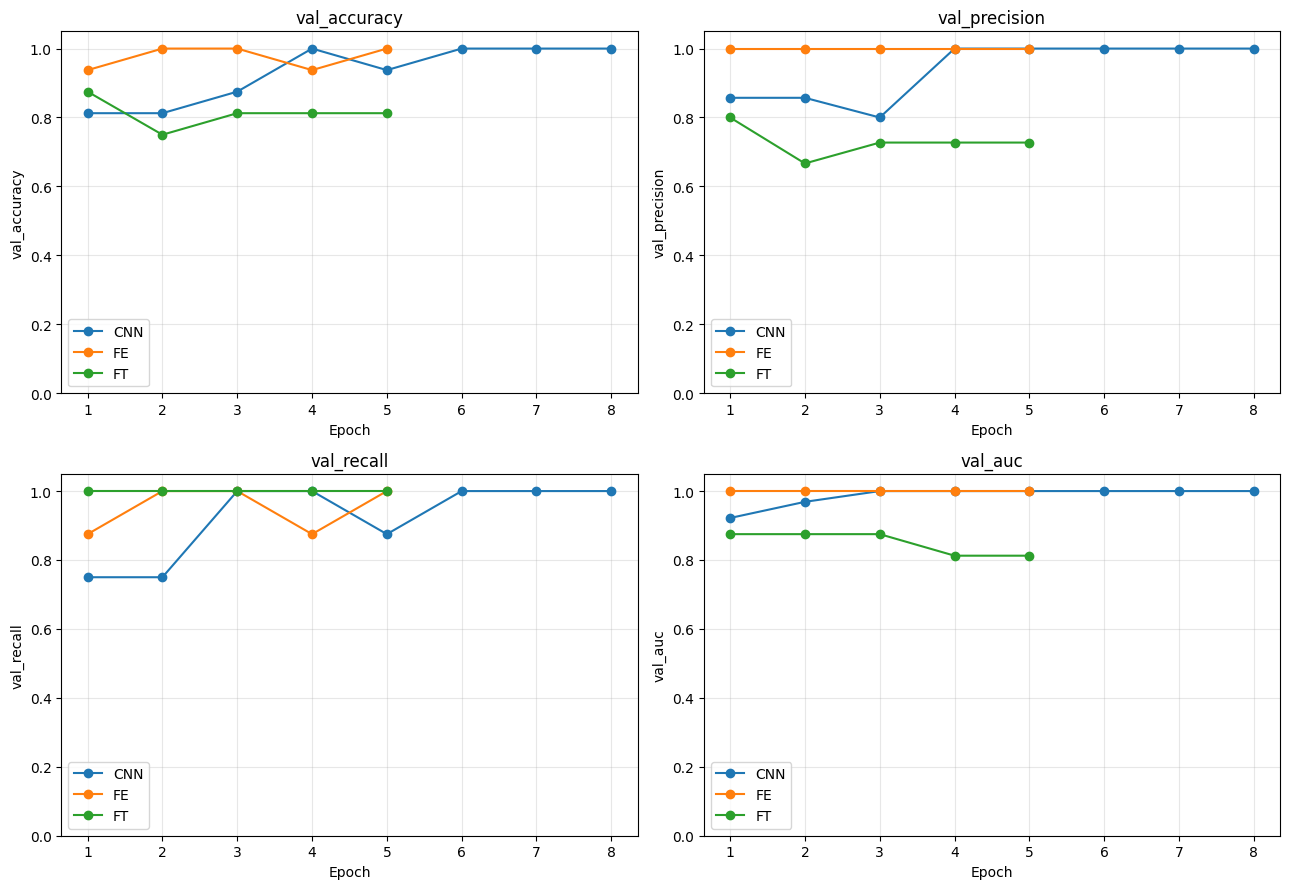

In [54]:

def draw_comparison_graphs(df):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, metric in zip(axes.flat, df.columns):
        for model in df.index:
            values = df.loc[model, metric]
            ax.plot(range(1, len(values) + 1), values, marker="o", label=model)
        ax.set_title(metric)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric)
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

draw_comparison_graphs(comparison_df)

In [55]:
def compare_2(model):

  test_metrics, test_proba, test_pred = evaluate(X_test, y_test, model)
  print(test_metrics)
  print(classification_report(y_test, test_pred, target_names=["NORMAL", "PNEUMONIA"]))
  ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["NORMAL", "PNEUMONIA"])
  plt.show()

In [57]:
models = {"CNN": cnn_model, "FE": joblib.load("fe_model.joblib"), "FT": ft_model}





metrics of CNN:

{'Accuracy': 0.7692307692307693, 'Precision': 0.7347328244274809, 'Recall': 0.9871794871794872, 'F1': 0.8424507658643327, 'ROC-AUC': np.float64(0.9235097523559063)}
              precision    recall  f1-score   support

      NORMAL       0.95      0.41      0.57       234
   PNEUMONIA       0.73      0.99      0.84       390

    accuracy                           0.77       624
   macro avg       0.84      0.70      0.71       624
weighted avg       0.82      0.77      0.74       624



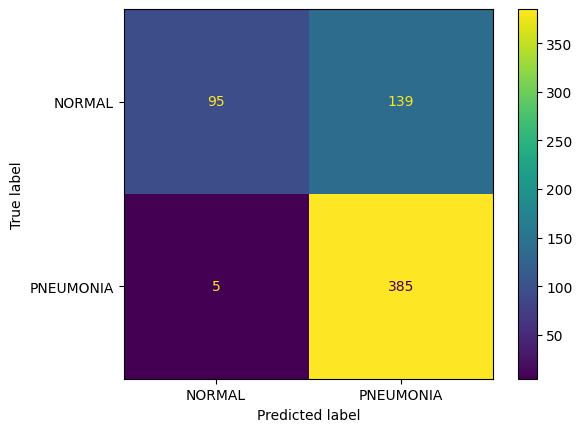




metrics of FE:

{'Accuracy': 0.8894230769230769, 'Precision': 0.8905109489051095, 'Recall': 0.9384615384615385, 'F1': 0.9138576779026217, 'ROC-AUC': np.float64(0.9557199211045365)}
              precision    recall  f1-score   support

      NORMAL       0.89      0.81      0.85       234
   PNEUMONIA       0.89      0.94      0.91       390

    accuracy                           0.89       624
   macro avg       0.89      0.87      0.88       624
weighted avg       0.89      0.89      0.89       624



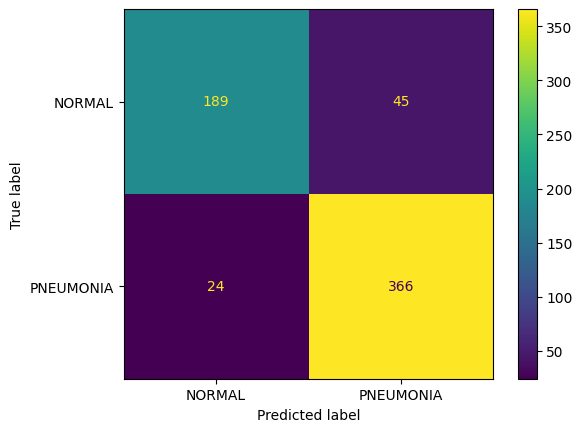




metrics of FT:

{'Accuracy': 0.8397435897435898, 'Precision': 0.803347280334728, 'Recall': 0.9846153846153847, 'F1': 0.8847926267281107, 'ROC-AUC': np.float64(0.9589634012710936)}
              precision    recall  f1-score   support

      NORMAL       0.96      0.60      0.74       234
   PNEUMONIA       0.80      0.98      0.88       390

    accuracy                           0.84       624
   macro avg       0.88      0.79      0.81       624
weighted avg       0.86      0.84      0.83       624



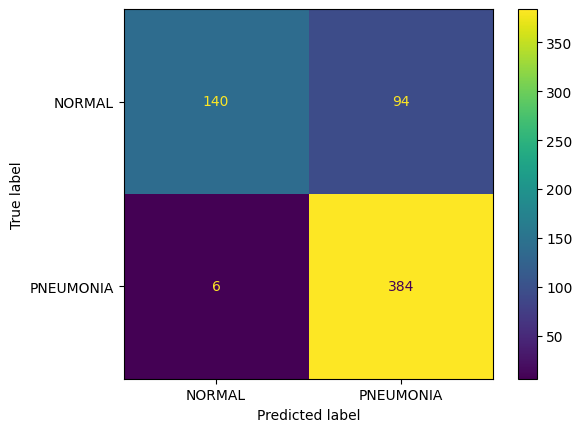

In [60]:
for name, model in models.items():
  print(f"\n\n\nmetrics of {name}:\n")
  compare_2(model)